In [97]:
%load_ext autoreload
%autoreload 2

import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision.utils as vutils
import torchvision.transforms as T
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from scipy import stats
from PIL import Image
import seaborn as sns

from compcats.datasets.fmri import nsd
from compcats.datasets.fmri.utils import nsd_ds_utils
from compcats.datasets.localization import vinken2023_localizer
from compcats.datasets.macaque import vinken2025
from compcats.encoder import encode
from compcats.utils import model_utils, responsecomparison_utils as rc_utils
from compcats.utils import reliability_utils as rel_utils
from compcats.models import  resnet50_openaiclip

sys.path.append('../preprint')
from preprint import paths
from preprint import main_analysis as ma

RESULTS_DIR = 'results/'
os.makedirs(RESULTS_DIR, exist_ok=True)
PLOTS_DIR = 'plots'
os.makedirs(PLOTS_DIR, exist_ok=True)

MODELS_DIR = '/Users/adipani3/projects/catsel/comparing-category-selectivity/preprint/models'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [128]:
froi = 'FFA' # EqUIVALENT TO ML (or CIT, from Vinken2023)

macaque_idx = 3
subject_idx = 1

model = resnet50_openaiclip.get_model()
layer = ma.get_froi_models_layers(froi, froi)[model.name]
transforms = model.transforms

In [94]:
# Helper functions

# Utils
# Get end to end torch encoding model
class e2e_em(torch.nn.Module):
    def __init__(self, model, layer, mapping_coef, mapping_intercept):
        super(e2e_em, self).__init__()
        self.model = model
        self.layer = layer
        
        # Convert sklearn mapping to torch.nn.Linear
        n_features = mapping_coef.shape[1]
        n_outputs = mapping_coef.shape[0]
        self.mapping_layer = torch.nn.Linear(n_features, n_outputs)
        
        # Set weights and bias from the sklearn model
        self.mapping_layer.weight.data = torch.FloatTensor(mapping_coef)
        self.mapping_layer.bias.data = torch.FloatTensor(mapping_intercept)
        
        # Get the layer module
        self.layer_module = dict([*self.model.model.named_modules()])[self.layer]
        
        # Register a forward hook to get the activations
        self.activations = None
        def hook(module, input, output):
            self.activations = output
        self.layer_module.register_forward_hook(hook)
    
    def forward(self, x):
        _ = self.model(x)
        # Get the activations
        x = self.activations
        x = x.reshape(x.shape[0], -1)
        # Apply the mapping directly with torch Linear layer
        x_mapped = self.mapping_layer(x)
        return x_mapped

# Probe dataset

(array(['human_faces', 'monkey_faces', 'nonfaces'], dtype='<U12'), array([230, 217, 932]))


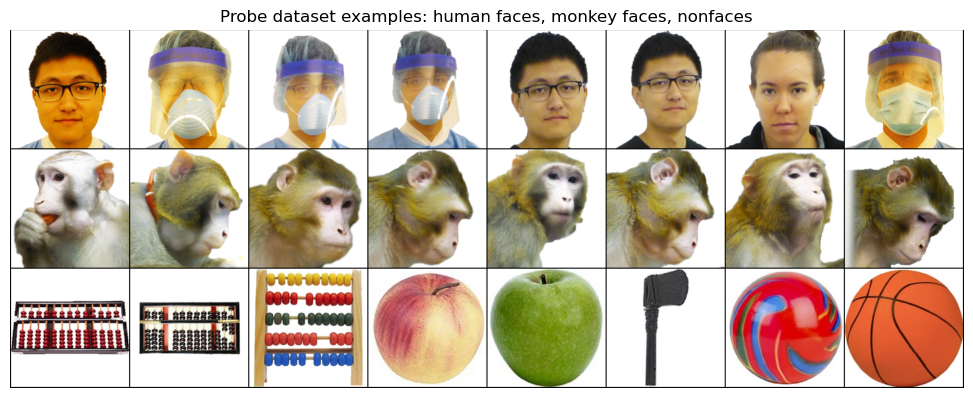

In [43]:
vinken23_ds = vinken2023_localizer.get_localizer_dataset(
    paths.VINKEN2023_LOCALIZER_DIR,
    transforms,
    image_class='all'
)
vinken23_ds_viz = vinken2023_localizer.get_localizer_dataset(
    paths.VINKEN2023_LOCALIZER_DIR,
    None,
    image_class='all'
)
vinken23_labels_str = np.array([vinken23_ds_viz.labels_names[label_idx-1] for label_idx in vinken23_ds_viz.image_labels])
print(np.unique(vinken23_labels_str, return_counts=True))
faceornot_labels = np.array(['face' if '_faces' in label else 'nonface' for label in vinken23_labels_str])

# Visualize some images
n_images = 8

to_tensor = T.ToTensor()  # PIL -> float tensor [C,H,W] in [0,1]

# Get 5 examples of faces and nonfaces, and plot using torchvision grid utils
humanface_indices = np.where(vinken23_labels_str == "human_faces")[0][:n_images]
monkeyface_indices = np.where(vinken23_labels_str == "monkey_faces")[0][:n_images]
nonface_indices = np.where(vinken23_labels_str == "nonfaces")[0][:n_images]
example_indices = np.concatenate([humanface_indices, monkeyface_indices, nonface_indices])

# PIL images
example_images_pil = [vinken23_ds_viz[i] for i in example_indices]

# convert to tensor batch [B,C,H,W]
example_images = torch.stack([to_tensor(img) for img in example_images_pil], dim=0)

grid_img = vutils.make_grid(example_images, nrow=n_images, padding=2)

plt.figure(figsize=(10, 4))
plt.imshow(grid_img.permute(1, 2, 0))
plt.axis("off")
plt.title("Probe dataset examples: human faces, monkey faces, nonfaces")
plt.tight_layout()
plt.show()

# Encoding models

In [82]:
alpha = 0.1
mapper = Ridge(alpha=alpha)

rthreshold = 0.4 # Reliability threshold
tthreshold = 7
nsd_subset = 1000

train_subset = 485
test_subset = 515

test_nsdids = nsd_ds_utils.get_subset_nsdids(paths.NSD_DIR, test_subset)

In [81]:
X_train = model_utils.get_dataset_activations(
    MODELS_DIR,
    paths.NSD_DIR,
    model,
    layer,
    'nsd',
    subset=train_subset
).flatten(start_dim=1)
X_test = model_utils.get_dataset_activations(
    MODELS_DIR,
    paths.NSD_DIR,
    model,
    layer,
    'nsd',
    subset=test_subset
).flatten(start_dim=1)

## Human

In [70]:
human_betas, human_df = nsd.get_betas(
    paths.NSD_DIR,
    subject_idx,
    froi,
    tthreshold=tthreshold,
    subset=nsd_subset,
    voxels=True,
    repetition_mean=False
)
human_train_idxs = human_df[~human_df['nsdId'].isin(test_nsdids)].index.values
human_test_idxs = human_df[human_df['nsdId'].isin(test_nsdids)].index.values

human_train_reliability = rel_utils.get_voxelwise_splithalf_correlation(human_betas[human_train_idxs])
human_reliable_voxel_mask = human_train_reliability >= rthreshold
print(f'Number of reliable voxels in {froi} for human subject {subject_idx}: {np.sum(human_reliable_voxel_mask)} out of {len(human_reliable_voxel_mask)}')
human_test_ceilings = rel_utils.get_voxelwise_splithalf_correlation(human_betas[human_test_idxs][:, :, human_reliable_voxel_mask])

human_train_responses = human_betas[human_train_idxs].mean(axis=1)[:, human_reliable_voxel_mask]
human_test_responses = human_betas[human_test_idxs].mean(axis=1)[:, human_reliable_voxel_mask]

Number of reliable voxels in FFA for human subject 1: 90 out of 156


In [95]:
human_em_mapper, human_train_metrics, human_test_metrics = encode.fit_eval_mapper(
    mapper,
    X_train.cpu().numpy(),
    human_train_responses,
    X_test.cpu().numpy(),
    human_test_responses,
)
human_test_scores = human_test_metrics/human_test_ceilings
print(f'Human subject {subject_idx} {froi} test scores (ceiling-normalized): {np.mean(human_test_scores):.4f} ± {np.std(human_test_scores):.4f}')

human_em = e2e_em(
    model,
    layer,
    human_em_mapper.coef_,
    human_em_mapper.intercept_
)

Human subject 1 FFA test scores (ceiling-normalized): 1.1143 ± 0.1056


## Macaque

In [139]:
macaque_train_responses, macaque_train_df = vinken2025.get_responses(
    paths.VINKEN2025_DIR,
    macaque_idx,
    froi=froi,
    subset=train_subset,
    rthreshold=rthreshold
)
macaque_test_responses, macaque_test_df = vinken2025.get_responses(
    paths.VINKEN2025_DIR,
    macaque_idx,
    froi=froi,
    subset=test_subset,
    rthreshold=rthreshold,
    repetition_mean=False
)
# assert macaque_train_responses.shape[-1] == macaque_test_responses.shape[-1], "Train and test responses must have same number of MUA channels"
# macaque_train_mean_reliability, macaque_train_reliability = vinken2025.get_splithalf_reliability(
#     paths.VINKEN2025_DIR,
#     'pearsonr',
#     macaque_idx,
#     froi=froi,
#     subset=train_subset
# )

In [140]:
macaque_test_responses.shape

(515, 33, 33)

In [135]:
a, b = vinken2025.get_splithalf_reliability(
    paths.VINKEN2025_DIR,
    'pearsonr',
    macaque_idx,
    froi=froi,
    subset=train_subset,
    rthreshold=rthreshold
)

In [131]:
macaque_train_mua.shape

(484, 33)

In [110]:
macaque_train_mua.shape

(484, 32)

In [114]:
macaque_train_reliability

array([0.84044049, 0.82181793, 0.85216316, 0.83375421, 0.82259549,
       0.83745785, 0.81378826, 0.81811531, 0.81637698, 0.83832829,
       0.82326894, 0.83436329, 0.81882849, 0.83832829, 0.82582635,
       0.84001406, 0.80029486, 0.83625055, 0.8398779 , 0.83452933,
       0.82812032, 0.8423206 , 0.81150526, 0.83117361, 0.82604404,
       0.83728922, 0.81470835, 0.81583099, 0.83119034, 0.82764832,
       0.83016252, 0.81271208, 0.8293246 , 0.8293438 , 0.82034431,
       0.82794083, 0.83736069, 0.82861632, 0.83242339, 0.82179833,
       0.83997808, 0.82973886, 0.81607453, 0.84554512, 0.84687189,
       0.83249322, 0.81976528, 0.82881314, 0.80264732, 0.81347387,
       0.81027149, 0.82704236, 0.82300642, 0.84065183, 0.82094192,
       0.82201205, 0.82729562, 0.81016298, 0.84373692, 0.83506008,
       0.8193259 , 0.84193192, 0.84016574, 0.80843234, 0.81263439,
       0.85727912, 0.81749642, 0.83226642, 0.8345979 , 0.82638012,
       0.81021559, 0.82606404, 0.80731428, 0.83632687, 0.82267